# Bayesian Linear Regression

We reuse the exact 100 observations from `../schr0841.github.io/GradientDescentBasic.ipynb`. Instead of finding only one best line, Bayesian regression infers a distribution over the intercept and slope.

Run all cells in order. Requirements: NumPy, Matplotlib, and Jupyter. The Gaussian model below has an exact analytical posterior, so no MCMC library is required.

## 1. The same sample data
Preserving the original seed, legacy NumPy generator, and draw order reproduces the data exactly. The generating line is $y=4+3x$ with independent standard Gaussian noise.

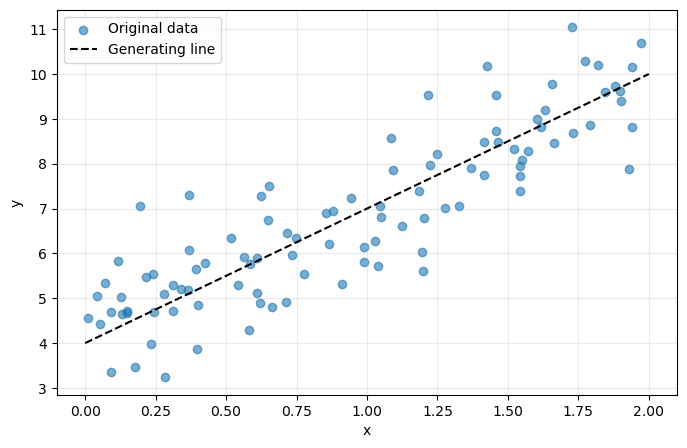

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)
X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1)
Phi = np.c_[np.ones((len(X), 1)), X]
target = y.ravel()
plt.figure(figsize=(8, 5))
plt.scatter(X.ravel(), target, alpha=0.6, label='Original data')
plt.plot([0, 2], [4, 10], 'k--', label='Generating line')
plt.xlabel('x'); plt.ylabel('y'); plt.legend(); plt.grid(alpha=0.25); plt.show()

## 2. Likelihood and prior
Let $\theta=[b,m]^T$ contain intercept and slope. The design matrix $\Phi$ has a column of ones and a column of feature values.

**Likelihood:** $\mathbf y\mid\theta\sim\mathcal N(\Phi\theta,\sigma^2 I)$. Errors are independent Gaussian observations with constant variance. We fix $\sigma=1$, the known generating noise standard deviation. In real applications this value is often unknown and should be estimated or inferred. All uncertainty here is conditional on it.

**Prior:** $\theta\sim\mathcal N(\mu_0,S_0)$, with $\mu_0=[0,0]^T$ and $S_0=10^2I$. This is a broad, proper prior with standard deviation 10 for each coefficient. It favors smaller coefficients without using the true values. Appropriate prior scales depend on the units of the features and target.

## 3. Bayes' rule and the exact posterior
$$p(\theta\mid\mathbf y,\Phi)=\frac{p(\mathbf y\mid\theta,\Phi)p(\theta)}{p(\mathbf y\mid\Phi)}.$$
The evidence in the denominator normalizes the distribution. Multiplying the Gaussian prior and likelihood and completing the square gives
$$S_N=(S_0^{-1}+\Phi^T\Phi/\sigma^2)^{-1},$$
$$\mu_N=S_N(S_0^{-1}\mu_0+\Phi^T\mathbf y/\sigma^2).$$
Thus $\theta\mid\mathbf y,\Phi\sim\mathcal N(\mu_N,S_N)$. Precision (inverse covariance) adds information from prior and data. The covariance describes both uncertainty in each coefficient and their correlation. We use linear solves for the calculation.

In [2]:
sigma = 1.0
mu0 = np.zeros(2)
S0 = 100.0 * np.eye(2)
def posterior(design, observations, prior_mean=mu0, prior_cov=S0, noise_sd=sigma):
    P0 = np.linalg.solve(prior_cov, np.eye(2))
    PN = P0 + design.T @ design / noise_sd**2
    SN = np.linalg.solve(PN, np.eye(2))
    muN = np.linalg.solve(PN, P0 @ prior_mean + design.T @ observations / noise_sd**2)
    return muN, SN
muN, SN = posterior(Phi, target)
sd = np.sqrt(np.diag(SN))
z = 1.959963984540054
ols = np.linalg.lstsq(Phi, target, rcond=None)[0]
for i, name in enumerate(['Intercept b', 'Slope m']):
    print(f'{name}: mean={muN[i]:.4f}, SD={sd[i]:.4f}, 95% credible interval=[{muN[i]-z*sd[i]:.4f}, {muN[i]+z*sd[i]:.4f}]')
print('OLS:', ols)
print('Posterior correlation:', SN[0,1]/(sd[0]*sd[1]))

Intercept b: mean=4.2144, SD=0.1876, 95% credible interval=[3.8466, 4.5821]
Slope m: mean=2.7705, SD=0.1689, 95% credible interval=[2.4395, 3.1014]
OLS: [4.21509616 2.77011339]
Posterior correlation: -0.8461899422631584


## 4. Interpret and visualize parameter uncertainty
A marginal 95% credible interval contains 95% of the posterior probability for that coefficient under this model and prior. Separate marginal intervals do not form a joint 95% region. The Gaussian posterior mean and mode coincide, and with this broad prior they are close to ordinary least squares.

The intercept and slope are correlated: a higher intercept can be offset by a lower slope in the observed range. The following draws are independent samples from the exact posterior, not an MCMC approximation.

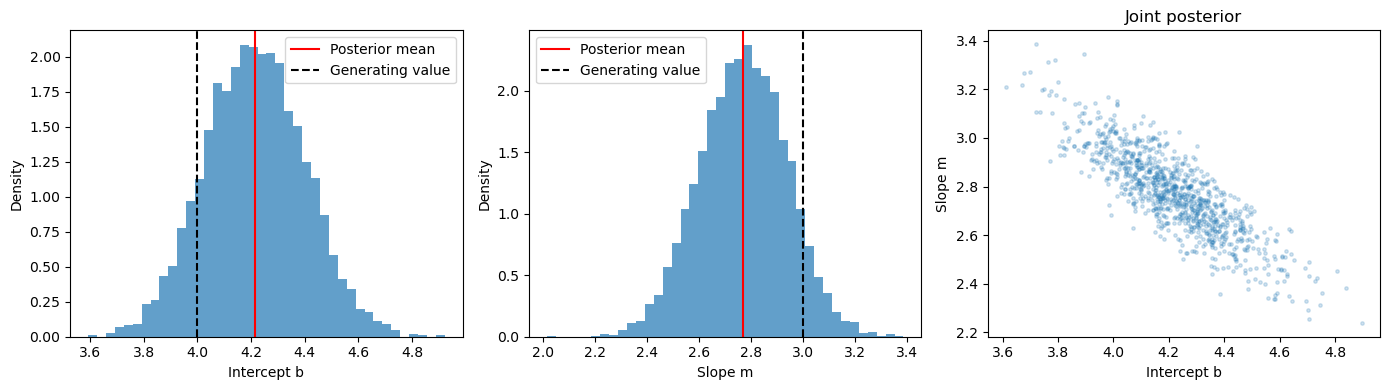

In [3]:
rng = np.random.default_rng(2026)  # Does not change the original data generator.
draws = rng.multivariate_normal(muN, SN, 4000)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for i, name in enumerate(['Intercept b', 'Slope m']):
    axes[i].hist(draws[:,i], bins=40, density=True, alpha=0.7)
    axes[i].axvline(muN[i], color='red', label='Posterior mean')
    axes[i].axvline([4,3][i], color='black', linestyle='--', label='Generating value')
    axes[i].set_xlabel(name); axes[i].set_ylabel('Density'); axes[i].legend()
axes[2].scatter(draws[::4,0], draws[::4,1], s=6, alpha=0.2)
axes[2].set_xlabel('Intercept b'); axes[2].set_ylabel('Slope m')
axes[2].set_title('Joint posterior')
fig.tight_layout(); plt.show()

## 5. Posterior prediction: two different uncertainties
For $\phi_*=[1,x_*]^T$, the underlying mean response has distribution
$$f_*\mid D\sim\mathcal N(\phi_*^T\mu_N,\phi_*^TS_N\phi_*).$$
A new noisy observation has distribution
$$y_*\mid D\sim\mathcal N(\phi_*^T\mu_N,\sigma^2+\phi_*^TS_N\phi_*).$$
The predictive interval adds observation noise to coefficient uncertainty and is therefore wider. These are pointwise 95% intervals, not simultaneous bands for the whole curve. Extrapolation increases coefficient uncertainty but does not account for a wrong linear model.

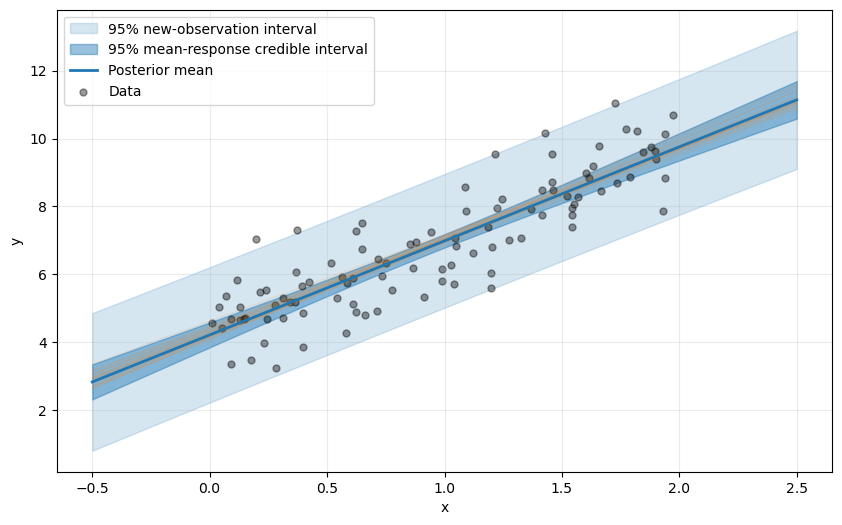

At x=1: predicted mean=6.985, mean-response SD=0.101, new-observation SD=1.005


In [4]:
grid = np.linspace(-0.5, 2.5, 250)
design = np.c_[np.ones(len(grid)), grid]
mean = design @ muN
variance = np.einsum('ij,jk,ik->i', design, SN, design)
mean_sd = np.sqrt(variance)
pred_sd = np.sqrt(variance + sigma**2)
plt.figure(figsize=(10, 6))
plt.fill_between(grid, mean-z*pred_sd, mean+z*pred_sd, alpha=0.18, color='tab:blue', label='95% new-observation interval')
plt.fill_between(grid, mean-z*mean_sd, mean+z*mean_sd, alpha=0.45, color='tab:blue', label='95% mean-response credible interval')
plt.plot(grid, design @ draws[:20].T, color='tab:orange', alpha=0.15, lw=0.8)
plt.plot(grid, mean, color='tab:blue', lw=2, label='Posterior mean')
plt.scatter(X.ravel(), target, color='black', alpha=0.4, s=25, label='Data')
plt.xlabel('x'); plt.ylabel('y'); plt.legend(); plt.grid(alpha=0.25); plt.show()
phi = np.array([1., 1.])
print(f'At x=1: predicted mean={phi @ muN:.3f}, mean-response SD={np.sqrt(phi @ SN @ phi):.3f}, new-observation SD={np.sqrt(sigma**2 + phi @ SN @ phi):.3f}')

## 6. Learning from more data
Each row starts from the same prior and uses the first n original observations. More data adds precision and reduces coefficient uncertainty; estimates need not approach the true values monotonically. Sequential updating equals batch updating under the same model and conditional independence assumptions.

In [5]:
print('  n    mean b    mean m      SD b      SD m')
for count in [0, 5, 20, 100]:
    mn, cov = posterior(Phi[:count], target[:count])
    sn = np.sqrt(np.diag(cov))
    print(f'{count:3d} {mn[0]:9.3f} {mn[1]:9.3f} {sn[0]:9.3f} {sn[1]:9.3f}')
m20, s20 = posterior(Phi[:20], target[:20])
ms, ss = posterior(Phi[20:], target[20:], m20, s20)
np.testing.assert_allclose(ms, muN, atol=1e-10)
np.testing.assert_allclose(ss, SN, atol=1e-10)
print('Sequential and batch posterior agree.')

  n    mean b    mean m      SD b      SD m
  0     0.000     0.000    10.000    10.000
  5     3.665     2.877     1.007     0.804
 20     4.360     2.445     0.407     0.372
100     4.214     2.770     0.188     0.169
Sequential and batch posterior agree.


## 7. Priors and regularization
For $S_0=\tau^2I$ and zero prior mean, the maximum a posteriori (MAP) estimate minimizes
$$\frac{1}{2\sigma^2}\|\mathbf y-\Phi\theta\|^2+\frac{1}{2\tau^2}\|\theta\|^2.$$
This corresponds to ridge regression with $\lambda=\sigma^2/\tau^2$ when the objective is squared-error sum plus $\lambda\|\theta\|^2$. Here **both intercept and slope are penalized**; many ridge implementations exclude the intercept. Larger prior scales approach OLS for a full-rank design; smaller scales shrink estimates toward zero.

In [6]:
print('Prior SD    mean b    mean m')
for tau in [0.1, 1., 10., 100.]:
    mt, _ = posterior(Phi, target, np.zeros(2), tau**2 * np.eye(2))
    print(f'{tau:8.1f} {mt[0]:9.4f} {mt[1]:9.4f}')
print('OLS:', ols)

Prior SD    mean b    mean m
     0.1    2.3143    2.3304
     1.0    4.1443    2.8014
    10.0    4.2144    2.7705
   100.0    4.2151    2.7701
OLS: [4.21509616 2.77011339]


## 8. Assumptions and experiments
This model assumes a linear mean, independent constant-variance Gaussian errors, a Gaussian coefficient prior, and known noise variance. Examine residual patterns in applications. A narrow posterior can still be misleading when the model is misspecified.

Gradient descent is an optimization algorithm; Bayesian inference updates probability distributions. They can be combined to find MAP estimates, but MAP alone does not describe the entire posterior. This conjugate Gaussian model needs neither gradient descent nor MCMC.

Try using only five observations, changing the prior scale, or increasing the assumed noise standard deviation and rerunning downstream cells. For unknown noise variance, an appropriate joint conjugate prior gives Student-t predictive distributions; more general models may require numerical inference.

The likelihood describes observations, the prior describes coefficients before seeing data, and the posterior combines them. Prediction includes both parameter uncertainty and observation noise.